# Dự đoán chuyển danh mục ở lượt click tiếp theo

## 1. Tổng quan dự án

### 1.1 Bài toán
Website có thể dựa vào hành vi duyệt sản phẩm để quyết định tiếp tục gợi ý danh mục hiện tại hay giới thiệu danh mục khác. Notebook dự đoán khả năng **Switch** ở lượt click tiếp theo; đây chưa phải một recommendation system hoàn chỉnh.

### 1.2 Câu hỏi nghiên cứu
> Thông tin của lượt click hiện tại và lịch sử duyệt trong session giúp dự đoán việc chuyển danh mục ở lượt click tiếp theo đến mức nào?

- **RQ1:** Chỉ dùng thông tin Current dự đoán Switch tốt đến đâu?
- **RQ2:** Thêm History có cải thiện kết quả không?

### 1.3 Target và thời điểm dự đoán
Ta dự đoán **sau khi ghi nhận click hiện tại, trước click kế tiếp**, với điều kiện session có click kế tiếp.

- `switch_category = 0` (**Stay**): click kế tiếp cùng danh mục.
- `switch_category = 1` (**Switch**): click kế tiếp khác danh mục; đây là positive class.

Click cuối session không có nhãn nên bị loại khỏi dữ liệu modeling. `next_category` chỉ dùng để tạo nhãn khi nghiên cứu, không có tại thời điểm dự đoán. Bài toán không dự đoán người dùng có kết thúc session hay không. Hai feature set dùng cùng những click đã gán nhãn và cùng train/test split.

## 2. Tìm hiểu dữ liệu

### 2.1 Import thư viện

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from sklearn.base import clone
from sklearn.svm import LinearSVC
from sklearn.model_selection import GroupShuffleSplit
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, roc_auc_score
)

sns.set_theme(style="whitegrid", palette="muted")
pd.set_option("display.max_columns", 14)

### 2.2 Đọc dữ liệu

In [2]:
df = pd.read_csv("e-shop clothing 2008.csv")
display(df.head())
print("Rows and columns:", df.shape)
print("Column names:", df.columns.tolist())

Rows and columns: (165474, 14)
Column names: ['year', 'month', 'day', 'order', 'country', 'session ID', 'page 1 (main category)', 'page 2 (clothing model)', 'colour', 'location', 'model photography', 'price', 'price 2', 'page']


,year,month,day,order,country,session ID,page 1 (main category),page 2 (clothing model),colour,location,model photography,price,price 2,page
0,2008,4,1,1,29,1,1,A13,1,5,1,28,2,1
1,2008,4,1,2,29,1,1,A16,1,6,1,33,2,1
2,2008,4,1,3,29,1,2,B4,10,2,1,52,1,1
3,2008,4,1,4,29,1,2,B17,6,6,2,38,2,1
4,2008,4,1,5,29,1,2,B8,4,3,2,52,1,1


### 2.3 Ý nghĩa các cột
Theo file `e-shop clothing 2008 data description.txt`, dữ liệu gốc có 14 cột:

| Cột | Ý nghĩa |
| --- | --- |
| `year`, `month`, `day` | Ngày ghi nhận click, trong năm 2008 |
| `order` | Vị trí click trong session |
| `country` | Quốc gia suy ra từ IP, chưa chắc là nơi cư trú |
| `session ID` | Mã session, không phải mã khách hàng lâu dài |
| `page 1 (main category)` | 1 = Trousers, 2 = Skirts, 3 = Blouses, 4 = Sale |
| `page 2 (clothing model)` | Mã mẫu sản phẩm |
| `colour` | Mã màu |
| `location` | Vị trí ảnh sản phẩm trên màn hình |
| `model photography` | Kiểu ảnh front hoặc profile |
| `price` | Giá hiện tại, USD |
| `price 2` | Giá cao hơn trung bình của danh mục hay không |
| `page` | Trang catalogue, từ 1 đến 5 |

Dữ liệu từ tháng 4 đến tháng 8 năm 2008. Một click thể hiện hành vi xem sản phẩm, không đồng nghĩa mua hàng.

### 2.4 Kiểm tra chất lượng dữ liệu

In [3]:
df.info()
display(df.isna().sum().rename("Missing values").to_frame())
print("Duplicate rows:", df.duplicated().sum())
print("Sessions:", df["session ID"].nunique())
print("Clothing models:", df["page 2 (clothing model)"].nunique())

assert not df.isna().any().any()
assert not df.duplicated().any()
assert not df.duplicated(["session ID", "order"]).any()
assert set(df["page 1 (main category)"]) == {1, 2, 3, 4}

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 165474 entries, 0 to 165473
Data columns (total 14 columns):
 #   Column                   Non-Null Count   Dtype 
---  ------                   --------------   ----- 
 0   year                     165474 non-null  int64 
 1   month                    165474 non-null  int64 
 2   day                      165474 non-null  int64 
 3   order                    165474 non-null  int64 
 4   country                  165474 non-null  int64 
 5   session ID               165474 non-null  int64 
 6   page 1 (main category)   165474 non-null  int64 
 7   page 2 (clothing model)  165474 non-null  object
 8   colour                   165474 non-null  int64 
 9   location                 165474 non-null  int64 
 10  model photography        165474 non-null  int64 
 11  price                    165474 non-null  int64 
 12  price 2                  165474 non-null  int64 
 13  page                     165474 non-null  int64 
dtypes: int64(13), object

,Missing values
year,0
month,0
day,0
order,0
country,0
session ID,0
page 1 (main category),0
page 2 (clothing model),0
colour,0
location,0


Dữ liệu gốc có 165.474 click thuộc 24.026 session; không có giá trị thiếu hay bản ghi trùng.

## 3. Tạo target và feature
Sắp xếp click theo session và `order` trước khi tạo nhãn. Thông tin của click kế tiếp chỉ tạo target, không đi vào feature.

### 3.1 Tạo target
Loại click cuối session trước khi gán `switch_category`; nếu không, giá trị `next_category` thiếu có thể bị gán nhầm thành Switch.

In [4]:
df = df.sort_values(["session ID", "order"]).copy()
df["next_category"] = df.groupby("session ID")["page 1 (main category)"].shift(-1)
df_model = df[df["next_category"].notna()].copy()
df_model["switch_category"] = (
    df_model["next_category"] != df_model["page 1 (main category)"]
).astype(int)

print("Raw clicks:", len(df))
print("Removed final clicks:", len(df) - len(df_model))
print("Rows with a target:", len(df_model))

Raw clicks: 165474
Removed final clicks: 24026
Rows with a target: 141448


### 3.2 Feature lịch sử
- `prev_category`: danh mục của click trước; 0 nghĩa là chưa có click trước.
- `same_category_prev`: -1 = chưa có click trước, 0 = khác, 1 = giống danh mục hiện tại.
- `category_visit_count`: số lần đã ghé danh mục hiện tại **trước click này**.

Lần ghé đầu tiên có count bằng 0. `cumcount()` không dùng click hiện tại hoặc tương lai.

In [5]:
df_model["prev_category"] = (
    df_model.groupby("session ID")["page 1 (main category)"].shift(1)
).fillna(0).astype(int)
df_model["same_category_prev"] = np.where(
    df_model["prev_category"] == 0,
    -1,
    (df_model["prev_category"] == df_model["page 1 (main category)"]).astype(int)
)
df_model["category_visit_count"] = (
    df_model.groupby(["session ID", "page 1 (main category)"]).cumcount()
)
print("Retained first clicks:", df_model["prev_category"].eq(0).sum())

Retained first clicks: 18984


### 3.3 Kiểm tra thứ tự click
Xem session 1 để kiểm tra target và feature lịch sử.

In [6]:
example_columns = [
    "session ID", "order", "page 1 (main category)", "prev_category",
    "same_category_prev", "category_visit_count", "next_category", "switch_category"
]
display(df_model.loc[df_model["session ID"].isin([1]), example_columns])

,session ID,order,page 1 (main category),prev_category,same_category_prev,category_visit_count,next_category,switch_category
0,1,1,1,0,-1,0,1.0,0
1,1,2,1,1,1,1,2.0,1
2,1,3,2,1,0,0,2.0,0
3,1,4,2,2,1,1,2.0,0
4,1,5,2,2,1,2,3.0,1
5,1,6,3,2,0,0,3.0,0
6,1,7,3,3,1,1,4.0,1
7,1,8,4,3,0,0,4.0,0


Ở session 1, click đầu không có danh mục trước và có count bằng 0. Click thứ hai đã ghé Trousers một lần và click kế tiếp chuyển sang Skirts. Click cuối dù bị loại khỏi tập modeling vẫn cung cấp nhãn cho click ngay trước nó.

## 4. Chia train/test theo session
`GroupShuffleSplit` chia nguyên session theo tỷ lệ 80/20. Test có 3.797 trong 18.984 session hợp lệ và 28.957 trong 141.448 click có nhãn (20,47%). Không có session trùng giữa train và test; nhiều session vẫn có thể thuộc cùng một người không xác định được.

In [7]:
splitter = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_index, test_index = next(
    splitter.split(df_model, groups=df_model["session ID"])
)
train_df = df_model.iloc[train_index].copy()
test_df = df_model.iloc[test_index].copy()
train_sessions = train_df["session ID"].unique()
test_sessions = test_df["session ID"].unique()

assert set(train_sessions).isdisjoint(set(test_sessions))
print("Train rows / sessions:", len(train_df), len(train_sessions))
print("Test rows / sessions:", len(test_df), len(test_sessions))
print("Overlapping sessions:", len(set(train_sessions) & set(test_sessions)))

Train rows / sessions: 112491 15187
Test rows / sessions: 28957 3797
Overlapping sessions: 0


## 5. Exploratory data analysis (EDA)
EDA chỉ dùng **train clicks có nhãn**. Mỗi tỷ lệ Switch cần đọc cùng số click của nhóm. Các click trong một session có liên quan và session dài đóng góp nhiều hàng hơn. Đây là mô tả mối liên hệ, không chứng minh quan hệ nhân quả hay hiệu quả trên test.

### 5.1 Phân bố target

,Count,Share (%)
switch_category,,
Stay,91257,81.12
Switch,21234,18.88


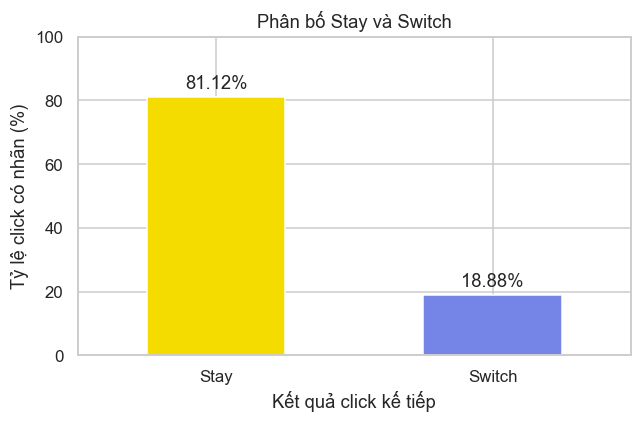

In [8]:
target_counts = train_df["switch_category"].value_counts().reindex([0, 1])
target_summary = pd.DataFrame({
    "Count": target_counts,
    "Share (%)": 100 * target_counts / target_counts.sum()
}).rename(index={0: "Stay", 1: "Switch"})
display(target_summary.round(2))

ax = target_summary["Share (%)"].plot.bar(rot=0, color=["#F5DC00", "#7484E7"], figsize=(6, 4))
ax.bar_label(ax.containers[0], fmt="%.2f%%", padding=3)
ax.set(title="Phân bố Stay và Switch", xlabel="Kết quả click kế tiếp", ylabel="Tỷ lệ click có nhãn (%)", ylim=(0, 100))
plt.tight_layout()
plt.show()

Switch chiếm 18,88% train clicks. Model luôn đoán Stay có thể đạt Accuracy cao nhưng bỏ sót mọi Switch. Vì vậy cần theo dõi Switch Precision, Recall và F1.

### 5.2 Switch rate theo danh mục hiện tại

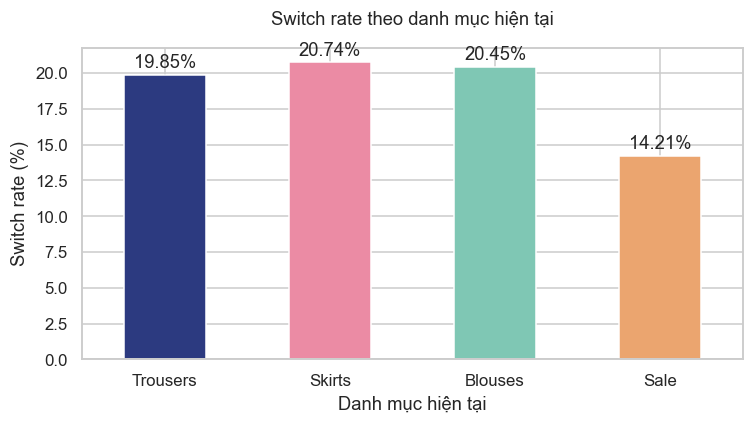

In [9]:
category_names = {1: "Trousers", 2: "Skirts", 3: "Blouses", 4: "Sale"}
category_rates = train_df.groupby("page 1 (main category)")["switch_category"].agg(
    ["size", "mean"]
).rename(index=category_names, columns={"size": "Clicks", "mean": "Switch rate"})
ax = (100 * category_rates["Switch rate"]).plot.bar(rot=0, color = ["#2C3A80", "#EB8BA4", "#7FC7B4", "#EBA56F"], figsize=(7, 4))
ax.bar_label(ax.containers[0], fmt="%.2f%%", padding=2)
ax.set_title("Switch rate theo danh mục hiện tại", pad=15)
ax.set(xlabel="Danh mục hiện tại", ylabel="Switch rate (%)")
plt.tight_layout()
plt.show()

Sale có Switch rate 14,21%, còn Skirts là 20,74%. Sự khác biệt này là lý do giữ danh mục hiện tại, nhưng chưa chứng minh danh mục gây ra thay đổi.

### 5.3 Switch rate theo vị trí click

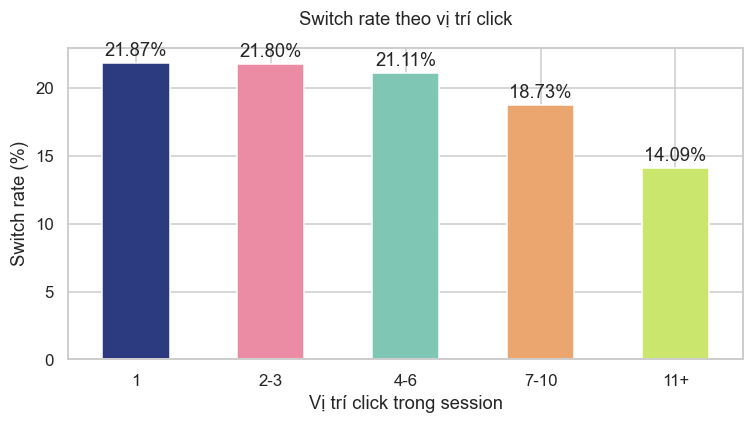

In [10]:
order_groups = pd.cut(
    train_df["order"], bins=[0, 1, 3, 6, 10, np.inf],
    labels=["1", "2-3", "4-6", "7-10", "11+"]
)
order_rates = train_df.groupby(order_groups, observed=True)["switch_category"].agg(
    ["size", "mean"]
)
ax = (100 * order_rates["mean"]).plot.bar(rot=0, color = ["#2C3A80", "#EB8BA4", "#7FC7B4", "#EBA56F", "#CAE66D"], figsize=(7, 4))
ax.bar_label(ax.containers[0], fmt="%.2f%%", padding=2)
ax.set_title("Switch rate theo vị trí click", pad=15)
ax.set(xlabel="Vị trí click trong session", ylabel="Switch rate (%)")
plt.tight_layout()
plt.show()

Switch rate giảm từ 21,87% ở click đầu xuống 14,09% từ vị trí 11. Giữ `order` làm bối cảnh hiện tại; nhóm click muộn cũng chỉ gồm những session đủ dài.

### 5.4 Switch rate theo danh mục trước

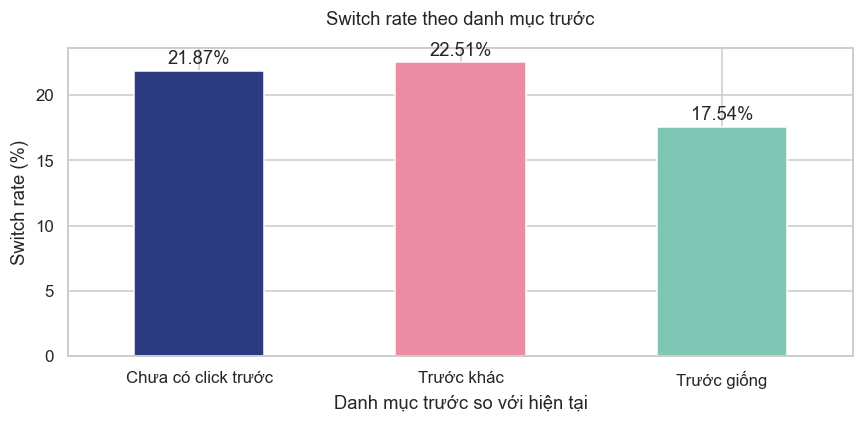

In [11]:
history_labels = {-1: "Chưa có click trước", 0: "Trước khác", 1: "Trước giống"}
consistency_rates = train_df.groupby("same_category_prev")["switch_category"].agg(
    ["size", "mean"]
).rename(index=history_labels)
ax = (100 * consistency_rates["mean"]).plot.bar(rot=0, color = ["#2C3A80", "#EB8BA4", "#7FC7B4"], figsize=(8, 4))
ax.bar_label(ax.containers[0], fmt="%.2f%%", padding=2)
ax.set_title("Switch rate theo danh mục trước", pad=15)
ax.set(xlabel="Danh mục trước so với hiện tại", ylabel="Switch rate (%)")
plt.tight_layout()
plt.show()

Switch rate là 22,51% sau khi vừa đổi danh mục, 17,54% sau khi giữ nguyên và 21,87% ở click đầu. Cần model comparison để biết thông tin này có thêm giá trị hay không.

### 5.5 Switch rate theo số lần ghé danh mục

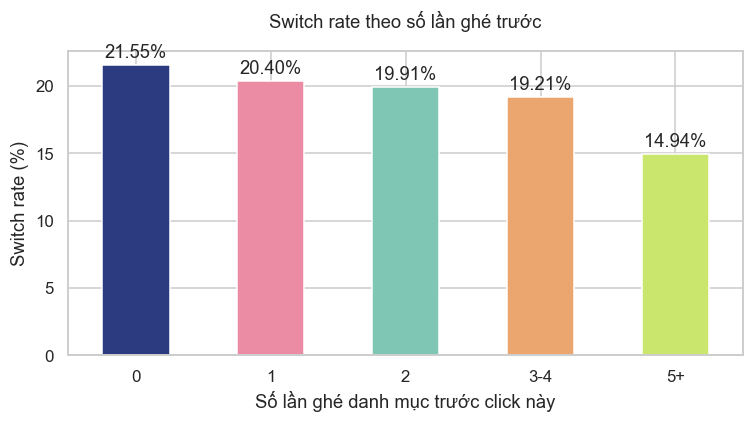

In [12]:
visit_groups = pd.cut(
    train_df["category_visit_count"], bins=[-1, 0, 1, 2, 4, np.inf],
    labels=["0", "1", "2", "3-4", "5+"]
)
visit_rates = train_df.groupby(visit_groups, observed=True)["switch_category"].agg(
    ["size", "mean"]
)
ax = (100 * visit_rates["mean"]).plot.bar(rot=0, color = ["#2C3A80", "#EB8BA4", "#7FC7B4", "#EBA56F", "#CAE66D"], figsize=(7, 4))
ax.bar_label(ax.containers[0], fmt="%.2f%%", padding=2)
ax.set_title("Switch rate theo số lần ghé trước", pad=15)
ax.set(xlabel="Số lần ghé danh mục trước click này", ylabel="Switch rate (%)")
plt.tight_layout()
plt.show()

Switch rate giảm từ 21,55% khi chưa từng ghé danh mục hiện tại xuống 14,94% khi đã ghé ít nhất năm lần. Feature này có thể trùng một phần thông tin với `order`.

### 5.6 Danh mục trước và hiện tại

Danh mục hiện tại,Trousers,Skirts,Blouses,Sale
Danh mục trước,,,,
Trousers,24312,2102,2099,1282
Skirts,1297,17700,1997,1026
Blouses,1397,1106,18536,1724
Sale,1008,933,1011,19774


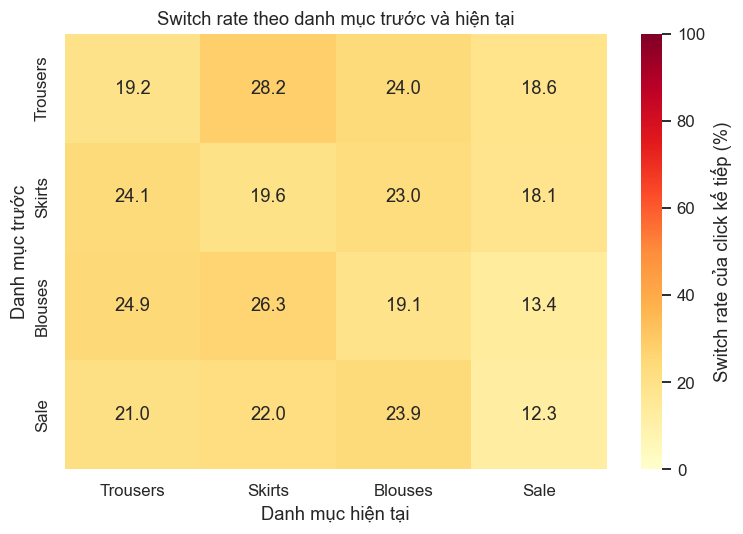

In [13]:
past_clicks = train_df[train_df["prev_category"] != 0]
transition_rates = past_clicks.pivot_table(
    index="prev_category", columns="page 1 (main category)",
    values="switch_category", aggfunc="mean"
).rename(index=category_names, columns=category_names)
transition_counts = past_clicks.pivot_table(
    index="prev_category", columns="page 1 (main category)",
    values="switch_category", aggfunc="size"
).rename(index=category_names, columns=category_names)
display(transition_counts.rename_axis(index="Danh mục trước", columns="Danh mục hiện tại"))
plt.figure(figsize=(7, 5))
sns.heatmap(100 * transition_rates, annot=True, fmt=".1f", cmap="YlOrRd",
            vmin=0, vmax=100, cbar_kws={"label": "Switch rate của click kế tiếp (%)"})
plt.title("Switch rate theo danh mục trước và hiện tại")
plt.xlabel("Danh mục hiện tại")
plt.ylabel("Danh mục trước")
plt.tight_layout()
plt.show()

Với cặp trước là Trousers và hiện tại là Skirts, 28,2% **click kế tiếp** là Switch. Đây không phải xác suất chuyển từ Trousers sang Skirts. Mỗi cặp hiển thị có ít nhất 933 click.

### 5.7 Giá và Switch

,median,mean
switch_category,,
Stay,43.0,43.65
Switch,43.0,44.25


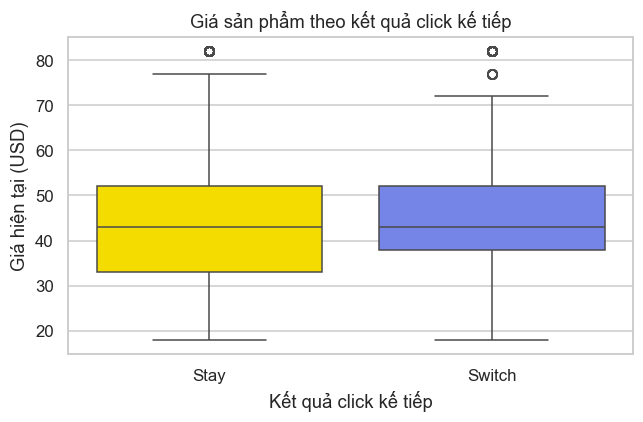

In [14]:
price_summary = train_df.groupby("switch_category")["price"].agg(["median", "mean"])
display(price_summary.rename(index={0: "Stay", 1: "Switch"}).round(2))
plt.figure(figsize=(6, 4))
sns.boxplot(data=train_df, x="switch_category", y="price", order=[0, 1], hue="switch_category", palette={0: "#F5DC00", 1: "#7484E7"}, saturation=1, legend=False)
plt.xticks([0, 1], ["Stay", "Switch"])
plt.title("Giá sản phẩm theo kết quả click kế tiếp")
plt.xlabel("Kết quả click kế tiếp")
plt.ylabel("Giá hiện tại (USD)")
plt.tight_layout()
plt.show()

Cả hai lớp có giá median 43 USD và phân bố chồng lấn nhiều. Vẫn giữ `price` trong tập Current để đánh giá cùng các feature khác.

### 5.8 Trang catalogue và Switch

,Clicks,Switch rate
page,,
1,63833,0.178
2,28181,0.179
3,13014,0.219
4,5809,0.255
5,1654,0.282


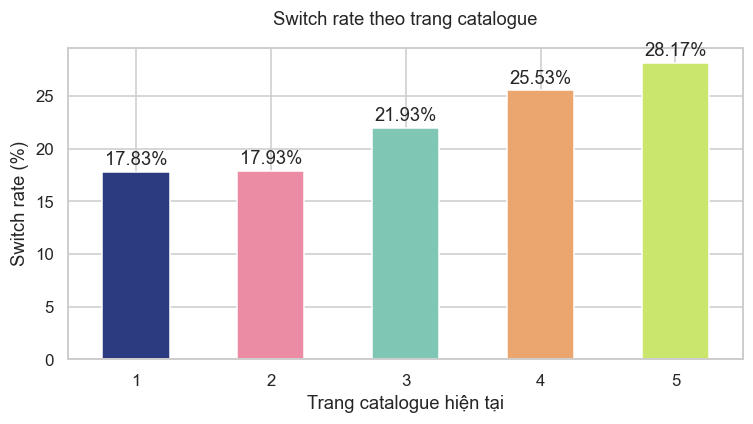

In [15]:
page_rates = train_df.groupby("page")["switch_category"].agg(["size", "mean"])
display(page_rates.rename(columns={"size": "Clicks", "mean": "Switch rate"}).round(3))
ax = (100 * page_rates["mean"]).plot.bar(rot=0, color = ["#2C3A80", "#EB8BA4", "#7FC7B4", "#EBA56F", "#CAE66D"], figsize=(7, 4))
ax.bar_label(ax.containers[0], fmt="%.2f%%", padding=2)
ax.set_title("Switch rate theo trang catalogue", pad=15)
ax.set(xlabel="Trang catalogue hiện tại", ylabel="Switch rate (%)")
plt.tight_layout()
plt.show()

Switch rate tăng từ 17,83% ở trang 1 lên 28,17% ở trang 5. Trang 5 chỉ có 1.654 click so với 63.833 ở trang 1; các trang cũng có thể khác về sản phẩm và danh mục.

### 5.9 Country
`country` suy ra từ IP và phân bố không đều. Bảng hiển thị 10 nhóm lớn nhất; dòng in bên dưới đếm các nhóm nhỏ.

In [16]:
def group_switch_summary(feature):
    summary = train_df.groupby(feature)["switch_category"].agg(["size", "mean"])
    summary = summary.rename(columns={"size": "Clicks", "mean": "Switch rate (%)"})
    summary["Share (%)"] = 100 * summary["Clicks"] / len(train_df)
    summary["Switch rate (%)"] *= 100
    return summary[["Clicks", "Share (%)", "Switch rate (%)"]]

country_summary = group_switch_summary("country").sort_values("Clicks", ascending=False)
display(country_summary.head(10).round(2))
print("Country groups:", len(country_summary))
print("Groups with fewer than 100 clicks:", (country_summary["Clicks"] < 100).sum())
print("Clicks in groups with fewer than 100:", country_summary.loc[country_summary["Clicks"] < 100, "Clicks"].sum())

Country groups: 40
Groups with fewer than 100 clicks: 25
Clicks in groups with fewer than 100: 824


,Clicks,Share (%),Switch rate (%)
country,,,
29,91157,81.03,19.18
9,12212,10.86,14.88
24,2837,2.52,19.84
46,1545,1.37,27.44
44,894,0.79,24.61
16,673,0.60,12.04
21,621,0.55,18.68
34,461,0.41,15.40
41,441,0.39,23.58


Mã country 29 chiếm 81,03% train clicks; 25 trong 40 mã có dưới 100 click. Loại `country` khỏi so sánh hành vi duyệt và thận trọng với tỷ lệ của nhóm nhỏ.

### 5.10 Thuộc tính sản phẩm và cách hiển thị
Các bảng sau cho biết số click và Switch rate theo `colour`, `location`, `model photography` và `price 2`.

In [17]:
colour_summary = group_switch_summary("colour").sort_values("Clicks", ascending=False)
location_summary = group_switch_summary("location").sort_values("Clicks", ascending=False)
photography_summary = group_switch_summary("model photography")
price2_summary = group_switch_summary("price 2")

print("Colour")
display(colour_summary.round(2))
print("Location")
display(location_summary.round(2))
print("Model photography")
display(photography_summary.round(2))
print("Price 2")
display(price2_summary.round(2))

Colour
Location
Model photography
Price 2


,Clicks,Share (%),Switch rate (%)
colour,,,
2,20313,18.06,17.87
3,20129,17.89,17.05
6,11604,10.32,23.66
4,11274,10.02,17.34
14,10703,9.51,20.31
9,9198,8.18,17.45
12,6003,5.34,17.44
1,5447,4.84,17.55
7,4639,4.12,19.59


,Clicks,Share (%),Switch rate (%)
location,,,
1,23623,21.00,18.95
2,22333,19.85,21.60
5,18959,16.85,18.60
4,18737,16.66,16.55
3,14788,13.15,16.92
6,14051,12.49,19.95


,Clicks,Share (%),Switch rate (%)
model photography,,,
1,83592,74.31,18.50
2,28899,25.69,19.96


,Clicks,Share (%),Switch rate (%)
price 2,,,
1,57401,51.03,19.01
2,55090,48.97,18.74


Switch rate theo `colour` từ 11,01% đến 31,30%, nhưng có thể bị ảnh hưởng bởi danh mục và sản phẩm. Theo `location`, tỷ lệ từ 16,55% đến 21,60%; hai kiểu ảnh có tỷ lệ 18,50% và 19,96%. Giữ ba thuộc tính này trong Current để đánh giá chung.

Hai nhóm `price 2` có tỷ lệ gần nhau, 19,01% và 18,74%. Loại feature này để giữ phạm vi nghiên cứu gọn; chưa kết luận nó không có giá trị dự đoán.

### 5.11 Tương quan số và kích thước nhóm
Xem bốn feature số cùng các nhóm có số click chênh lệch nhiều. Mã danh mục không được xem là số liên tục.

In [18]:
numeric_features = ["order", "price", "page", "category_visit_count"]
display(train_df[numeric_features].corr().round(3))

size_audit = pd.DataFrame({
    name: {"Smallest group": counts.min(), "Largest group": counts.max()}
    for name, counts in {
        "Country": train_df.groupby("country").size(),
        "Colour": train_df.groupby("colour").size(),
        "Catalogue page": train_df.groupby("page").size(),
    }.items()
}).T
display(size_audit)

,order,price,page,category_visit_count
order,1.000,-0.069,0.218,0.745
price,-0.069,1.000,-0.155,-0.045
page,0.218,-0.155,1.000,0.268
category_visit_count,0.745,-0.045,0.268,1.000


,Smallest group,Largest group
Country,1,91157
Colour,1080,20313
Catalogue page,1654,63833


`order` và `category_visit_count` có Pearson 0,745 nhưng diễn tả hai khía cạnh khác nhau. Tương quan không đủ để quyết định loại feature. Các nhóm country rất nhỏ cần được diễn giải thận trọng.

## 6. Chọn feature và khả năng sử dụng
Dự đoán ngay sau click hiện tại. **Current** dùng bảy thông tin của click này; **Current + History** thêm ba feature từ click hiện tại và trước đó. Dữ liệu offline chưa cho biết độ trễ ghi nhận trong hệ thống thực tế.

| Nhóm | Feature | Lý do |
| --- | --- | --- |
| Current | `page 1 (main category)`, `order`, `price`, `colour`, `location`, `model photography`, `page` | Đã biết khi click hiện tại được ghi nhận; mô tả danh mục, vị trí và sản phẩm |
| History | `prev_category`, `same_category_prev`, `category_visit_count` | Tính từ click trước và danh mục hiện tại; count không gồm click hiện tại |

**Quyết định giữ/loại:** `prev_category` và `same_category_prev` có phần thông tin trùng nhau, nhưng có cách biểu diễn khác nhau cho model. `country` lệch nhóm và nằm ngoài trọng tâm hành vi duyệt; `page 2 (clothing model)` có 217 mã nên nằm ngoài bộ feature gọn. `price 2` có thể hữu ích nhưng chưa được kiểm chứng thêm. `year` là hằng số; `month`, `day` cần một đánh giá theo thời gian riêng. `session ID` chỉ dùng để chia nhóm; `next_category` chỉ tạo nhãn; `switch_category` là target. Không chọn feature chỉ từ tương quan hay EDA.

In [19]:
current_features = [
    "page 1 (main category)", "order", "price", "colour",
    "location", "model photography", "page"
]
current_history_features = current_features + [
    "prev_category", "same_category_prev", "category_visit_count"
]

current_categorical = [
    "page 1 (main category)", "colour", "location", "model photography"
]
current_numerical = ["order", "price", "page"]
history_categorical = current_categorical + ["prev_category", "same_category_prev"]
history_numerical = current_numerical + ["category_visit_count"]

Các mã danh mục, kể cả ba trạng thái của `same_category_prev`, được xử lý như categorical features. `order`, `price`, `page` và visit count là numerical features.

In [20]:
X_train_current = train_df[current_features]
X_test_current = test_df[current_features]
X_train_history = train_df[current_history_features]
X_test_history = test_df[current_history_features]
y_train = train_df["switch_category"]
y_test = test_df["switch_category"]

print("Current features:", len(current_features))
print("Current + history features:", len(current_history_features))

# Target distribution in train and test sets
target_distribution = pd.DataFrame({
    "Train Count": y_train.value_counts().reindex([0, 1], fill_value=0),
    "Train (%)": y_train.value_counts(normalize=True).reindex([0, 1], fill_value=0) * 100,
    "Test Count": y_test.value_counts().reindex([0, 1], fill_value=0),
    "Test (%)": y_test.value_counts(normalize=True).reindex([0, 1], fill_value=0) * 100
})

target_distribution.index = ["Stay (0)", "Switch (1)"]

display(target_distribution.round(2))

Current features: 7
Current + history features: 10


,Train Count,Train (%),Test Count,Test (%)
Stay (0),91257,81.12,23666,81.73
Switch (1),21234,18.88,5291,18.27


In [21]:
print(X_train_current.shape)
print(X_test_current.shape)
print(X_train_history.shape)
print(X_test_history.shape)
print(y_train.shape)
print(y_test.shape)

(112491, 7)
(28957, 7)
(112491, 10)
(28957, 10)
(112491,)
(28957,)


## 7. Phát triển model
Model selection, tuning, ablation và chọn threshold chỉ dùng train. Test được dùng ở Section 10 để đánh giá một lần theo kế hoạch đã chọn. Chỉ số chính là Switch F1; Precision, Recall, Accuracy, Macro F1 và ROC-AUC giúp hiểu trade-off.

### 7.1 GroupKFold và kiểm tra leakage
Năm fold không trùng session, dùng chung cho các model. Feature lịch sử chỉ dùng click trước; session ID và thông tin click kế tiếp không đi vào model.

In [22]:
from sklearn.model_selection import GroupKFold
from sklearn.metrics import make_scorer, precision_score, recall_score, f1_score

RANDOM_STATE = 42
groups = train_df["session ID"].to_numpy()
group_cv = GroupKFold(n_splits=5)
folds = list(group_cv.split(X_train_history, y_train, groups))

In [23]:
excluded_cols = {"session ID", "next_category", "switch_category"}

assert excluded_cols.isdisjoint(X_train_current.columns)
assert excluded_cols.isdisjoint(X_train_history.columns)

print("Feature leakage check passed.")

Feature leakage check passed.


In [24]:
# Mỗi session chỉ xuất hiện ở một phía của mỗi fold.
for fold, (train_idx, val_idx) in enumerate(folds, 1):
    train_sessions_fold = set(groups[train_idx])
    val_sessions = set(groups[val_idx])
    overlap = train_sessions_fold & val_sessions
    assert not overlap
    print(f"Fold {fold}: train {len(train_sessions_fold)} session, "
          f"validation {len(val_sessions)} session, overlap = {len(overlap)}")

Fold 1: train 12149 session, validation 3038 session, overlap = 0
Fold 2: train 12150 session, validation 3037 session, overlap = 0
Fold 3: train 12150 session, validation 3037 session, overlap = 0
Fold 4: train 12150 session, validation 3037 session, overlap = 0
Fold 5: train 12149 session, validation 3038 session, overlap = 0


In [25]:
scoring = {
    "Switch Precision": make_scorer(
        precision_score, pos_label=1, zero_division=0
    ),
    "Switch Recall": make_scorer(
        recall_score, pos_label=1, zero_division=0
    ),
    "Switch F1": make_scorer(
        f1_score, pos_label=1, zero_division=0
    ),
    "Macro F1": make_scorer(
        f1_score, average="macro", zero_division=0
    ),
    "Accuracy": "accuracy",
    "ROC-AUC": "roc_auc"
}

### 7.2 Baseline luôn đoán Stay

In [26]:
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import cross_validate

always_stay = DummyClassifier(strategy="constant", constant=0)
cv_stay = cross_validate(always_stay, X_train_current, y_train,
                         cv=folds, scoring=scoring)
stay_result = {
    "Model": "Always-Stay",
    "Switch Precision": cv_stay["test_Switch Precision"].mean(),
    "Switch Recall": cv_stay["test_Switch Recall"].mean(),
    "Switch F1": cv_stay["test_Switch F1"].mean(),
    "Macro F1": cv_stay["test_Macro F1"].mean(),
    "Accuracy": cv_stay["test_Accuracy"].mean(),
}
display(pd.DataFrame([stay_result]).round(4))

,Model,Switch Precision,Switch Recall,Switch F1,Macro F1,Accuracy
0,Always-Stay,0.0,0.0,0.0,0.4479,0.8112


### 7.3 Preprocessing trong từng fold
`StandardScaler` áp dụng cho feature số của linear models; `OneHotEncoder` áp dụng cho categorical features. Với tree models, feature số được giữ nguyên. Mọi transformer nằm trong `Pipeline`, nên mỗi fold chỉ fit trên phần train của fold đó.

In [27]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

linear_current = ColumnTransformer([
    ("num", StandardScaler(), current_numerical),
    ("cat", OneHotEncoder(handle_unknown="ignore"), current_categorical)
])

linear_history = ColumnTransformer([
    ("num", StandardScaler(), history_numerical),
    ("cat", OneHotEncoder(handle_unknown="ignore"), history_categorical)
])

tree_current = ColumnTransformer([
    ("num", "passthrough", current_numerical),
    ("cat", OneHotEncoder(handle_unknown="ignore"), current_categorical)
])

tree_history = ColumnTransformer([
    ("num", "passthrough", history_numerical),
    ("cat", OneHotEncoder(handle_unknown="ignore"), history_categorical)
])

In [28]:
rf_params = {
    "n_estimators": 200,
    "max_depth": 12,
    "min_samples_split": 10,
    "min_samples_leaf": 5,
    "max_features": "sqrt",
    "random_state": RANDOM_STATE,
    "n_jobs": -1
}

logreg_params = {
    "C": 1.0,
    "solver": "lbfgs",
    "max_iter": 1000,
    "random_state": RANDOM_STATE
}

dt_params = {
    "max_depth": 6,
    "min_samples_split": 10,
    "min_samples_leaf": 5,
    "criterion": "gini",
    "random_state": RANDOM_STATE
}

svm_params = {
    "C": 1.0,
    "loss": "squared_hinge",
    "tol": 1e-3,
    "max_iter": 10000,
    "random_state": RANDOM_STATE
}

In [29]:
logreg = Pipeline([
    ("preprocessor", linear_current),
    ("model", LogisticRegression(
        class_weight="balanced",
        **logreg_params
    ))
])


decision_tree = Pipeline([
    ("preprocessor", tree_current),
    ("model", DecisionTreeClassifier(
        class_weight="balanced",
        **dt_params
    ))
])

random_forest = Pipeline([
    ("preprocessor", tree_current),
    ("model", RandomForestClassifier(
        class_weight="balanced",
        **rf_params
    ))
])

linear_svm = Pipeline([
    ("preprocessor", linear_current),
    ("model", LinearSVC(
        class_weight="balanced",
        **svm_params
    ))
])

logreg_normal = Pipeline([
    ("preprocessor", linear_current),
    ("model", LogisticRegression(
        class_weight=None,
        **logreg_params
    ))
])

rf_normal = Pipeline([
    ("preprocessor", tree_current),
    ("model", RandomForestClassifier(
        class_weight=None,
        **rf_params
    ))
])

logreg_history = Pipeline([
    ("preprocessor", linear_history),
    ("model", LogisticRegression(
        class_weight="balanced",
        **logreg_params
    ))
])

decision_tree_history = Pipeline([
    ("preprocessor", tree_history),
    ("model", DecisionTreeClassifier(
        class_weight="balanced",
        **dt_params
    ))
])

random_forest_history = Pipeline([
    ("preprocessor", tree_history),
    ("model", RandomForestClassifier(
        class_weight="balanced",
        **rf_params
    ))
])

linear_svm_history = Pipeline([
    ("preprocessor", linear_history),
    ("model", LinearSVC(
        class_weight="balanced",
        **svm_params
    ))
])

logreg_history_normal = Pipeline([
    ("preprocessor", linear_history),
    ("model", LogisticRegression(
        class_weight=None,
        **logreg_params
    ))
])

rf_history_normal = Pipeline([
    ("preprocessor", tree_history),
    ("model", RandomForestClassifier(
        class_weight=None,
        **rf_params
    ))
])

### 7.4 Tác động của class weight lên Logistic Regression

In [30]:
# Cùng folds và feature set; chỉ class_weight thay đổi.
imbalance_models = {
    "Current": (X_train_current, logreg_normal, logreg),
    "Current + History": (X_train_history, logreg_history_normal, logreg_history),
}
imbalance_results = []
for feature_set, (X, normal_model, balanced_model) in imbalance_models.items():
    for label, model in [("Normal", normal_model), ("Balanced", balanced_model)]:
        cv = cross_validate(model, X, y_train, cv=folds, scoring=scoring)
        imbalance_results.append({
            "Feature set": feature_set,
            "Logistic Regression": label,
            "Switch Precision": cv["test_Switch Precision"].mean(),
            "Switch Recall": cv["test_Switch Recall"].mean(),
            "Switch F1": cv["test_Switch F1"].mean(),
            "Macro F1": cv["test_Macro F1"].mean(),
            "Accuracy": cv["test_Accuracy"].mean(),
            "ROC-AUC": cv["test_ROC-AUC"].mean(),
        })
imbalance_results = pd.DataFrame(imbalance_results)
display(imbalance_results.round(4))

,Feature set,Logistic Regression,Switch Precision,Switch Recall,Switch F1,Macro F1,Accuracy,ROC-AUC
0,Current,Normal,0.0000,0.0000,0.0000,0.4479,0.8112,0.6113
1,Current,Balanced,0.2356,0.5977,0.3380,0.5030,0.5579,0.6115
2,Current + History,Normal,0.4691,0.0009,0.0019,0.4488,0.8112,0.6213
3,Current + History,Balanced,0.2406,0.6162,0.3461,0.5075,0.5604,0.6216


**Nhận xét:** Với Current, class weight balanced tăng Switch F1 từ 0 lên 0,3380 và Recall từ 0 lên 0,5977. Với Current + History, Switch F1 tăng từ 0,0019 lên 0,3461. Accuracy giảm do model dự đoán nhiều Switch hơn. Bảng này chỉ so sánh Logistic Regression; Random Forest được xem ở Section 8.

## 8. So sánh model trên train folds

In [31]:
models_history = {
    "Logistic Regression": logreg_history,
    "Decision Tree": decision_tree_history,
    "Random Forest": random_forest_history,
    "Linear SVM": linear_svm_history
}

In [32]:
model_results = []

for name, model in models_history.items():
    cv = cross_validate(
        model,
        X_train_history,
        y_train,
        groups=groups,
        cv=folds,
        scoring=scoring
    )

    model_results.append({
        "Model": name,
        "CV Switch F1 Mean": cv["test_Switch F1"].mean(),
        "CV Switch F1 Std": cv["test_Switch F1"].std(),
        "CV Precision Mean": cv["test_Switch Precision"].mean(),
        "CV Recall Mean": cv["test_Switch Recall"].mean(),
        "CV Macro F1 Mean": cv["test_Macro F1"].mean(),
        "CV ROC-AUC Mean": cv["test_ROC-AUC"].mean()
    })

model_results = pd.DataFrame(model_results).sort_values(
    "CV Switch F1 Mean",
    ascending=False
)

display(model_results.round(4))

,Model,CV Switch F1 Mean,CV Switch F1 Std,CV Precision Mean,CV Recall Mean,CV Macro F1 Mean,CV ROC-AUC Mean
2,Random Forest,0.3693,0.0098,0.2671,0.5987,0.5456,0.6535
3,Linear SVM,0.3462,0.0070,0.2407,0.6162,0.5076,0.6214
0,Logistic Regression,0.3461,0.0070,0.2406,0.6162,0.5075,0.6216
1,Decision Tree,0.3432,0.0094,0.2378,0.6422,0.4910,0.6196


In [33]:
best_model_name = model_results.iloc[0]["Model"]

print("Selected model:", best_model_name)
print(
    "Mean CV Switch F1:",
    round(model_results.iloc[0]["CV Switch F1 Mean"], 4)
)

Selected model: Random Forest
Mean CV Switch F1: 0.3693


## 9. Tuning và chọn feature trên train

### 9.1 Tuning hyperparameter

In [34]:
from sklearn.model_selection import RandomizedSearchCV

# Search đúng Pipeline được sử dụng khi đánh giá cuối.
rf_pipeline = Pipeline([
    ("preprocessor", tree_history),
    ("model", RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1)),
])
param_distributions = {
    "model__n_estimators": [100, 200],
    "model__max_depth": [10, 12, 20],
    "model__min_samples_split": [5, 10],
    "model__min_samples_leaf": [4, 5, 8],
    "model__max_features": ["sqrt", "log2"],
    "model__class_weight": ["balanced", "balanced_subsample"],
}
random_search = RandomizedSearchCV(
    estimator=rf_pipeline,
    param_distributions=param_distributions,
    n_iter=4,
    scoring=scoring["Switch F1"],
    cv=folds,
    n_jobs=1,
    random_state=RANDOM_STATE,
    refit=True,
)
random_search.fit(X_train_history, y_train)
print("Best parameters:", random_search.best_params_)
print("Best CV Switch F1:", round(random_search.best_score_, 4))

Best parameters: {'model__n_estimators': 200, 'model__min_samples_split': 10, 'model__min_samples_leaf': 5, 'model__max_features': 'log2', 'model__max_depth': 10, 'model__class_weight': 'balanced'}
Best CV Switch F1: 0.3697


**Kết quả tuning:** Random Forest dùng cùng `Pipeline` có `OneHotEncoder` ở CV và đánh giá cuối. Trong bốn cấu hình được thử, cấu hình tốt nhất có 200 cây, `max_depth=10`, `min_samples_split=10`, `min_samples_leaf=5`, `max_features="log2"` và `class_weight="balanced"`. Mean CV Switch F1 là **0,3697**. Search này có phạm vi gọn cho báo cáo tiến độ, không phải tìm kiếm toàn bộ không gian tham số. Điểm CV dùng để chọn cấu hình, chưa phải ước lượng độc lập sau khi lựa chọn.

### 9.2 OOF probability và chọn threshold

In [35]:
tuned_rf = clone(random_search.best_estimator_)

In [36]:
from sklearn.model_selection import cross_val_predict

oof_prob_rf = cross_val_predict(
    tuned_rf, X_train_history, y_train, cv=folds,
    method="predict_proba", n_jobs=1
)[:, 1]

In [37]:
thresholds = np.arange(0.10, 0.81, 0.01)
threshold_results_rf = []
for threshold in thresholds:
    pred = (oof_prob_rf >= threshold).astype(int)
    threshold_results_rf.append({
        "Threshold": threshold,
        "Switch Precision": precision_score(y_train, pred, zero_division=0),
        "Switch Recall": recall_score(y_train, pred, zero_division=0),
        "Switch F1": f1_score(y_train, pred, zero_division=0),
    })
threshold_results_rf = pd.DataFrame(threshold_results_rf)
best_row_rf = threshold_results_rf.loc[threshold_results_rf["Switch F1"].idxmax()]
best_threshold_rf = float(best_row_rf["Threshold"])
print(f"Threshold được chọn trên train: {best_threshold_rf:.2f}")
print(f"OOF Switch F1: {best_row_rf['Switch F1']:.4f}")

Threshold được chọn trên train: 0.50
OOF Switch F1: 0.3697


**Kết quả chọn threshold:** OOF trên train chọn **0,50**, với Switch F1 **0,3697**. Đây cũng là threshold mặc định của phân loại nhị phân. Hyperparameter và threshold cùng được chọn bằng train folds, nên điểm OOF này có thể lạc quan; test chưa được dùng.

### 9.3 Ablation của History

In [38]:
history_features = ["prev_category", "same_category_prev", "category_visit_count"]
feature_groups = [
    (),
    ("category_visit_count",),
    ("prev_category", "category_visit_count"),
    tuple(history_features),
]

def make_rf_pipeline(added_features):
    categorical = current_categorical + [
        col for col in ("prev_category", "same_category_prev")
        if col in added_features
    ]
    numerical = current_numerical + (["category_visit_count"]
                                     if "category_visit_count" in added_features else [])
    preprocessor = ColumnTransformer([
        ("num", "passthrough", numerical),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical),
    ])
    return Pipeline([
        ("preprocessor", preprocessor),
        ("model", clone(random_search.best_estimator_.named_steps["model"])),
    ])

ablation_results = []
for added_features in feature_groups:
    X = train_df[current_features + list(added_features)]
    oof_prob = cross_val_predict(
        make_rf_pipeline(added_features), X, y_train,
        cv=folds, method="predict_proba", n_jobs=1
    )[:, 1]
    pred = (oof_prob >= best_threshold_rf).astype(int)
    ablation_results.append({
        "Added History": "None" if not added_features else " + ".join(added_features),
        "Switch Precision": precision_score(y_train, pred, zero_division=0),
        "Switch Recall": recall_score(y_train, pred, zero_division=0),
        "Switch F1": f1_score(y_train, pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_train, oof_prob),
    })
ablation_results = pd.DataFrame(ablation_results).sort_values(
    "Switch F1", ascending=False
).reset_index(drop=True)
display(ablation_results.round(4))

,Added History,Switch Precision,Switch Recall,Switch F1,ROC-AUC
0,prev_category + same_category_prev + category_visit_count,0.2636,0.6186,0.3697,0.6524
1,prev_category + category_visit_count,0.2611,0.6290,0.3690,0.6512
2,category_visit_count,0.2598,0.6251,0.3670,0.6498
3,None,0.2578,0.6054,0.3616,0.6433


In [39]:
best_ablation = ablation_results.iloc[0]
print("Feature set được chọn:", best_ablation["Added History"])
print(f"OOF Switch F1 dùng để chọn: {best_ablation['Switch F1']:.4f}")

Feature set được chọn: prev_category + same_category_prev + category_visit_count
OOF Switch F1 dùng để chọn: 0.3697


**Kết quả ablation:** Trong bốn cấu hình thử, Current + cả ba History feature đứng đầu với OOF Switch F1 **0,3697**; Current đơn thuần đạt **0,3616**. `prev_category + category_visit_count` đạt **0,3690**, rất gần cấu hình đứng đầu. Chênh lệch OOF dùng để **chọn** feature set, không đủ để kết luận History cải thiện ngoài mẫu. So sánh test ở Section 10 sẽ kiểm tra điều đó.

### 9.4 Chốt cấu hình trước khi xem test
Random Forest được chọn theo CV Switch F1. Trong bốn cấu hình ablation, cả ba History feature đứng đầu; threshold chọn trên train là **0,50**. Hai model Current và Current + History ở Section 10 dùng cùng hyperparameter và threshold 0,50, chỉ khác feature set. Test không được dùng để chọn lại cấu hình.

## 10. Fit cuối và đánh giá trên test

### 10.1 So sánh Current và feature set đã chọn
Hai model có cùng Random Forest hyperparameter và threshold 0,5. Chỉ feature set khác nhau. Bảng này trả lời RQ2 trên test; không dùng test để chọn lại model.

In [40]:
selected_history = ([] if best_ablation["Added History"] == "None"
                    else best_ablation["Added History"].split(" + "))
final_features = current_features + selected_history
final_model = make_rf_pipeline(selected_history)
current_test_model = make_rf_pipeline([])
print("History đã chọn:", selected_history)
print("Threshold đã chọn trên train:", round(best_threshold_rf, 2))

History đã chọn: ['prev_category', 'same_category_prev', 'category_visit_count']
Threshold đã chọn trên train: 0.5


In [41]:
X_train_final = train_df[final_features]
X_test_final = test_df[final_features]
final_model.fit(X_train_final, y_train)
current_test_model.fit(X_train_current, y_train)

In [42]:
test_prob = final_model.predict_proba(X_test_final)[:, 1]
current_test_prob = current_test_model.predict_proba(X_test_current)[:, 1]
test_pred = (test_prob >= best_threshold_rf).astype(int)

In [43]:
# So sánh RQ2 tại cùng threshold 0,5; cấu hình đã chốt trước khi xem test.
def test_metrics(name, probability, threshold):
    prediction = (probability >= threshold).astype(int)
    return {
        "Model": name,
        "Threshold": threshold,
        "Switch Precision": precision_score(y_test, prediction, zero_division=0),
        "Switch Recall": recall_score(y_test, prediction, zero_division=0),
        "Switch F1": f1_score(y_test, prediction, zero_division=0),
        "Macro F1": f1_score(y_test, prediction, average="macro", zero_division=0),
        "Accuracy": accuracy_score(y_test, prediction),
        "ROC-AUC": roc_auc_score(y_test, probability),
    }

test_comparison = pd.DataFrame([
    test_metrics("Current", current_test_prob, 0.5),
    test_metrics("Current + selected History", test_prob, 0.5),
])
display(test_comparison.round(4))

final_test_results = pd.DataFrame([
    test_metrics("Final model", test_prob, best_threshold_rf)
])
print("Model cuối tại threshold đã chọn trên train:")
display(final_test_results.round(4))

Model cuối tại threshold đã chọn trên train:


,Model,Threshold,Switch Precision,Switch Recall,Switch F1,Macro F1,Accuracy,ROC-AUC
0,Current,0.5,0.2545,0.6118,0.3594,0.5352,0.6016,0.6509
1,Current + selected History,0.5,0.2608,0.6186,0.3669,0.5426,0.6100,0.6607


,Model,Threshold,Switch Precision,Switch Recall,Switch F1,Macro F1,Accuracy,ROC-AUC
0,Final model,0.5,0.2608,0.6186,0.3669,0.5426,0.61,0.6607


### 10.2 Confusion matrix của model cuối

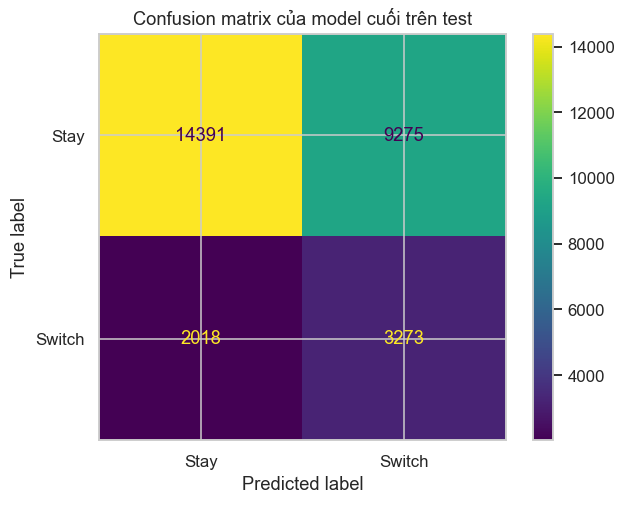

In [44]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test, test_pred, display_labels=["Stay", "Switch"]
)
plt.title("Confusion matrix của model cuối trên test")
plt.show()

Confusion matrix cho thấy model nhận diện được khoảng **61,86%** Switch thật, nhưng Switch Precision chỉ **26,08%**: nhiều dự đoán Switch là false positives. Vì vậy cần đọc Precision và Recall cùng nhau, không chỉ nhìn Accuracy.

### 10.3 Classification report

In [45]:
print(classification_report(
    y_test, test_pred, target_names=["Stay", "Switch"], digits=4
))

              precision    recall  f1-score   support

        Stay     0.8770    0.6081    0.7182     23666
      Switch     0.2608    0.6186    0.3669      5291

    accuracy                         0.6100     28957
   macro avg     0.5689    0.6133    0.5426     28957
weighted avg     0.7644    0.6100    0.6540     28957



Trên test, model cuối đạt Switch Precision **0,2608**, Recall **0,6186**, F1 **0,3669**, Accuracy **0,6100** và ROC-AUC **0,6607**. Model bắt được khoảng 62% Switch thật nhưng còn nhiều false positives. Baseline luôn đoán Stay có Accuracy cao hơn vì lớp Stay chiếm đa số; Switch F1 của baseline bằng 0.

### 10.4 Feature importance

In [46]:
feature_names = final_model.named_steps[
    "preprocessor"
].get_feature_names_out()

importances = final_model.named_steps[
    "model"
].feature_importances_

feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
})

def get_original_feature(name):
    name = name.replace("num__", "").replace("cat__", "")

    for col in final_features:
        if name == col or name.startswith(col + "_"):
            return col

    return name


feature_importance["Original Feature"] = (
    feature_importance["Feature"]
    .apply(get_original_feature)
)

original_importance = (
    feature_importance
    .groupby("Original Feature", as_index=False)["Importance"]
    .sum()
    .sort_values("Importance", ascending=False)
)

display(original_importance.round(4))

,Original Feature,Importance
4,order,0.1869
5,page,0.1411
0,category_visit_count,0.1352
1,colour,0.1200
7,prev_category,0.0997
6,page 1 (main category),0.0956
2,location,0.0758
8,price,0.0712
9,same_category_prev,0.0480
3,model photography,0.0264


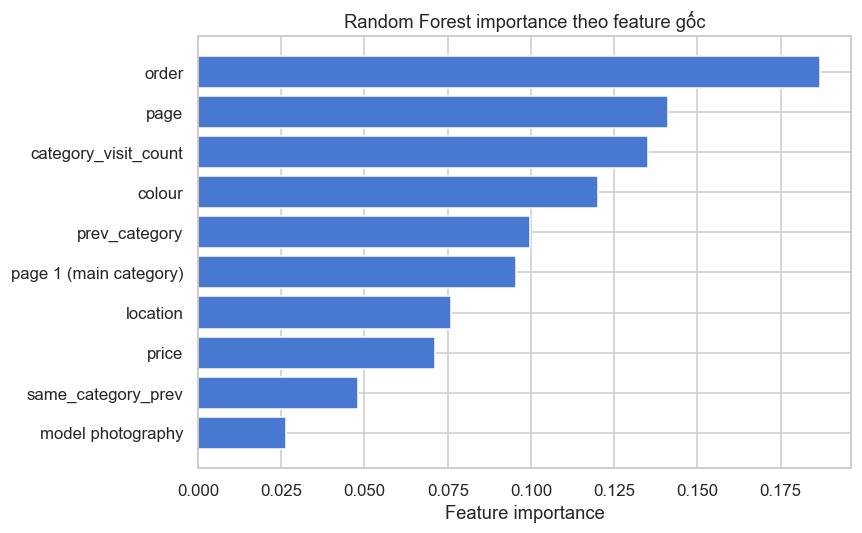

In [47]:
plot_data = original_importance.sort_values("Importance")
plt.figure(figsize=(8, 5))
plt.barh(plot_data["Original Feature"], plot_data["Importance"])
plt.xlabel("Feature importance")
plt.title("Random Forest importance theo feature gốc")
plt.tight_layout()
plt.show()

Feature importance của Random Forest xếp `order` cao nhất (**0,1869**), tiếp theo là `page` (**0,1411**) và `category_visit_count` (**0,1352**). Đây là mức đóng góp vào việc chia cây trên train, không chứng minh quan hệ nhân quả hay giá trị độc lập của từng feature. Đóng góp tổng thể của History được kiểm tra bằng so sánh test ở Section 10.

## 11. Trả lời câu hỏi nghiên cứu
**RQ1:** Với Current, test Switch F1 là **0,3594**, Precision **0,2545** và Recall **0,6118**. Current chứa tín hiệu dự đoán nhưng vẫn tạo nhiều false positives.

**RQ2:** Với cùng Random Forest hyperparameter và threshold 0,50, thêm ba History feature làm test Switch F1 tăng từ **0,3594** lên **0,3669**, tức **0,0075 điểm F1**. ROC-AUC tăng từ **0,6509** lên **0,6607**. Kết quả test ủng hộ một cải thiện nhỏ; một lần chia test chưa đủ để khẳng định cải thiện ổn định trên dữ liệu khác.

## 12. Hạn chế
- `session ID` không phải mã người dùng, nên không kiểm soát được cùng một người ở nhiều session.
- Bài toán có điều kiện là còn click kế tiếp; chưa dự đoán kết thúc session.
- Dữ liệu năm 2008 có thể không đại diện cho website hiện nay.
- Switch ít hơn Stay; Precision và Recall đánh đổi với nhau.
- Search chỉ thử bốn cấu hình, ablation chỉ thử bốn feature set; kết quả không phải tối ưu toàn cục.
- Feature importance của Random Forest không phải bằng chứng nhân quả.

## 13. Hướng phát triển
Thử History dài hơn, dữ liệu mới hơn và đánh giá theo thời gian. Nếu có thông tin mua hàng hoặc khách hàng, cần thiết kế bài toán và cách chia dữ liệu phù hợp trước khi thêm feature.

## 14. Kết luận
Model cuối dùng Random Forest với Current và ba History feature, threshold **0,50**. Trên test, Switch F1 là **0,3669**, Recall **0,6186** và Precision **0,2608**. History cải thiện Switch F1 **0,0075** so với Current dưới cùng cấu hình; mức cải thiện nhỏ và cần kiểm chứng trên dữ liệu mới. Precision còn thấp, nên chưa nên xem đây là hệ thống gợi ý sản phẩm sẵn sàng sử dụng.

**Nguồn dữ liệu:** `e-shop clothing 2008 data description.txt`. Tài liệu tham khảo gợi ý: Łapczyński, M. và Białowąs, S. (2013), *Discovering Patterns of Users' Behaviour in an E-shop – Comparison of Consumer Buying Behaviours in Poland and Other European Countries*, Studia Ekonomiczne 151, 144–153.